In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk


In [3]:
def split_bilateral(image_path, label_path, output_dir="./bilateral_data"):

    # Read image and label
    image = sitk.ReadImage(image_path)
    label = sitk.ReadImage(label_path)

    # Verify matching geometry
    if (
        image.GetSize() != label.GetSize()
        or not np.allclose(image.GetSpacing(), label.GetSpacing())
        or not np.allclose(image.GetOrigin(), label.GetOrigin())
        or not np.allclose(image.GetDirection(), label.GetDirection())
    ):
        raise ValueError("Image and label geometry do not match!")

    # Convert to NumPy (Z, Y, X)
    image_array = sitk.GetArrayViewFromImage(image)

    z = image_array.shape[0] // 2
    width = image.GetSize()[0]

    # Display middle slice with grid
    fig, ax = plt.subplots(figsize=(12, 9))

    ax.imshow(image_array[z], cmap="gray")
    ax.axvline(width / 2, color="red", linestyle="--",
               label="50% (center)")

    ax.set_title(f"Middle Slice {z} - Select Breast Separation")
    ax.set_xlabel("X voxel coordinate")
    ax.set_ylabel("Y voxel coordinate")

    ax.set_xticks(np.arange(0, width + 1, 20))
    ax.set_yticks(np.arange(0, image_array.shape[1] + 1, 20))

    ax.grid(True, color="yellow", alpha=0.4, linestyle="--")
    ax.legend()

    plt.show()

    # Ask user for percentage
    percentage = float(input(
        "Enter percentage of image width for LEFT side (e.g. 50): "
    ))

    if not 0 < percentage < 100:
        raise ValueError("Percentage must be between 0 and 100.")

    split_x = round(width * percentage / 100)

    print(f"Image width: {width}")
    print(f"Selected percentage: {percentage}%")
    print(f"Splitting at X = {split_x}")

    # Crop image and label with SimpleITK
    sx, sy, sz = image.GetSize()

    first_size = [split_x, sy, sz]
    second_size = [sx - split_x, sy, sz]

    image_first = sitk.RegionOfInterest(image, first_size, [0, 0, 0])
    image_second = sitk.RegionOfInterest(image, second_size, [split_x, 0, 0])

    label_first = sitk.RegionOfInterest(label, first_size, [0, 0, 0])
    label_second = sitk.RegionOfInterest(label, second_size, [split_x, 0, 0])

    # Determine anatomical left/right from image orientation
    direction = np.array(image.GetDirection()).reshape(3, 3)

    if abs(direction[0, 0]) < 0.8:
        raise ValueError("Image X-axis is not aligned with anatomical left/right.")

    if direction[0, 0] > 0:
        left_image, right_image = image_second, image_first
        left_label, right_label = label_second, label_first
    else:
        left_image, right_image = image_first, image_second
        left_label, right_label = label_first, label_second

    # Create output directories
    image_dir = os.path.join(output_dir, "imagesTr")
    label_dir = os.path.join(output_dir, "labelsTr")

    os.makedirs(image_dir, exist_ok=True)
    os.makedirs(label_dir, exist_ok=True)

    # Save image and corresponding label
    image_name = os.path.basename(image_path)
    label_name = os.path.basename(label_path)

    for side, img, lbl in [
        ("left", left_image, left_label),
        ("right", right_image, right_label)
    ]:

        image_output = os.path.join(image_dir, f"{side}_{image_name}")
        label_output = os.path.join(label_dir, f"{side}_{label_name}")

        sitk.WriteImage(img, image_output, useCompression=True)
        sitk.WriteImage(lbl, label_output, useCompression=True)

        print(f"Saved: {image_output}")
        print(f"Saved: {label_output}")

    print("Bilateral splitting completed!")

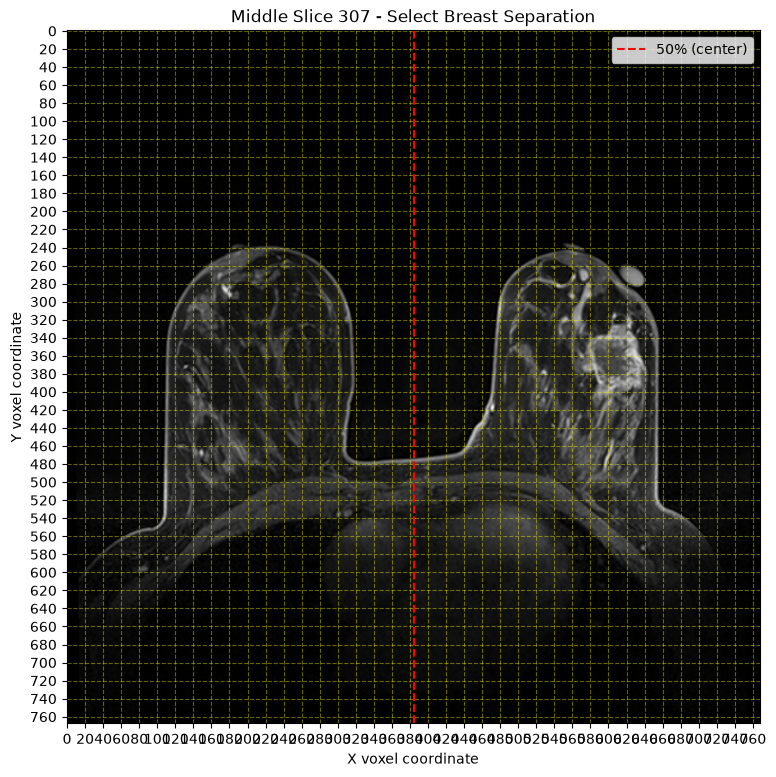

Image width: 768
Selected percentage: 50.0%
Splitting at X = 384
Saved: /root/RL/segmentation/data/nnUNet_raw/Dataset002_dartmouth_bilateral_mixed/imagesTr/left_case_045_0_0000.nii.gz
Saved: /root/RL/segmentation/data/nnUNet_raw/Dataset002_dartmouth_bilateral_mixed/labelsTr/left_case_045_0.nii.gz
Saved: /root/RL/segmentation/data/nnUNet_raw/Dataset002_dartmouth_bilateral_mixed/imagesTr/right_case_045_0_0000.nii.gz
Saved: /root/RL/segmentation/data/nnUNet_raw/Dataset002_dartmouth_bilateral_mixed/labelsTr/right_case_045_0.nii.gz
Bilateral splitting completed!


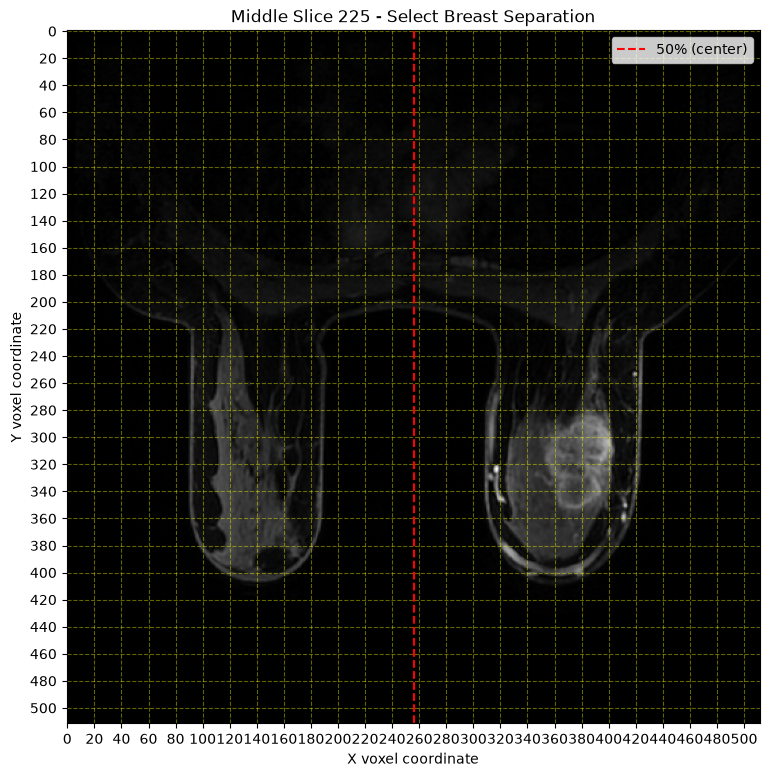

Image width: 512
Selected percentage: 50.0%
Splitting at X = 256
Saved: /root/RL/segmentation/data/nnUNet_raw/Dataset002_dartmouth_bilateral_mixed/imagesTr/left_case_049_0_0000.nii.gz
Saved: /root/RL/segmentation/data/nnUNet_raw/Dataset002_dartmouth_bilateral_mixed/labelsTr/left_case_049_0.nii.gz
Saved: /root/RL/segmentation/data/nnUNet_raw/Dataset002_dartmouth_bilateral_mixed/imagesTr/right_case_049_0_0000.nii.gz
Saved: /root/RL/segmentation/data/nnUNet_raw/Dataset002_dartmouth_bilateral_mixed/labelsTr/right_case_049_0.nii.gz
Bilateral splitting completed!


In [4]:
image_dir = "/root/RL/segmentation/data/nnUNet_raw/Dataset001_dartmouth/imagesTs"
output_dir = "/root/RL/segmentation/data/nnUNet_raw/Dataset002_dartmouth_bilateral_mixed"
for files in os.listdir(image_dir):
    image_path = os.path.join(image_dir, files)
    label_path = os.path.join("/root/RL/segmentation/data/labelsTs", files.replace("_0000", ""))
    split_bilateral(image_path, label_path, output_dir=output_dir)